# 1. Very small gradients in layers closer to the input

In [11]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons

# Load built-in dataset
data = load_breast_cancer()
# X,y = make_moons(n_samples=250, noise=0.05, random_state=42)

X = data.data.astype("float32")
y = data.target.reshape(-1, 1).astype("float32")

# Split data before scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)


Training data: (455, 30)
Test data: (114, 30)


In [12]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],))
])

# 15 hidden layers
for _ in range(15):
    model.add(
        tf.keras.layers.Dense(
            32,
            activation="sigmoid",
            kernel_initializer="glorot_uniform"
        )
    )

# Binary classification output
model.add(
    tf.keras.layers.Dense(1, activation="sigmoid")
)

model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_32 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,809 (61.75 KB)

 Trainable params: 15,809 (61.75 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Measure gradients directly using backpropagation
# TensorFlow's GradientTape lets us inspect the gradients calculated during backpropagation without manually implementing the chain rule.

def get_layer_gradients(model, X, y):
    # Use one mini-batch
    X_batch = tf.convert_to_tensor(X[:64])
    y_batch = tf.convert_to_tensor(y[:64])

    with tf.GradientTape() as tape:
        predictions = model(X_batch, training=True)

        loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(
                y_batch, predictions
            )
        )

    variables = model.trainable_variables
    gradients = tape.gradient(loss, variables)

    results = []

    for layer in model.layers:
        if not isinstance(layer, tf.keras.layers.Dense):
            continue

        # Find the gradient corresponding to this layer's weights
        kernel = layer.kernel
        idx = next(
            i for i, variable in enumerate(variables)
            if variable is kernel
        )

        grad = gradients[idx]

        results.append({
            "layer": layer.name,
            "mean_abs_gradient": float(
                tf.reduce_mean(tf.abs(grad)).numpy()
            ),
            "gradient_norm": float(
                tf.linalg.global_norm([grad]).numpy()
            )
        })

    return pd.DataFrame(results), float(loss.numpy())


gradient_df, initial_loss = get_layer_gradients(
    model, X_train, y_train
)

print("Initial loss:", initial_loss)
print(gradient_df.to_string(index=False))

Initial loss: 0.6459935903549194
   layer  mean_abs_gradient  gradient_norm
dense_32       5.378939e-12   2.475429e-10
dense_33       5.211996e-12   2.843640e-10
dense_34       1.046121e-11   5.363687e-10
dense_35       4.112282e-11   1.713905e-09
dense_36       2.116014e-10   8.401734e-09
dense_37       9.176236e-10   4.045001e-08
dense_38       3.616299e-09   1.526498e-07
dense_39       1.949103e-08   8.289233e-07
dense_40       9.979867e-08   3.966474e-06
dense_41       3.431067e-07   1.450423e-05
dense_42       1.682860e-06   7.246291e-05
dense_43       6.814562e-06   2.915177e-04
dense_44       2.654985e-05   1.163845e-03
dense_45       1.632485e-04   6.777294e-03
dense_46       7.578068e-04   2.947654e-02
dense_47       1.684491e-02   9.795861e-02


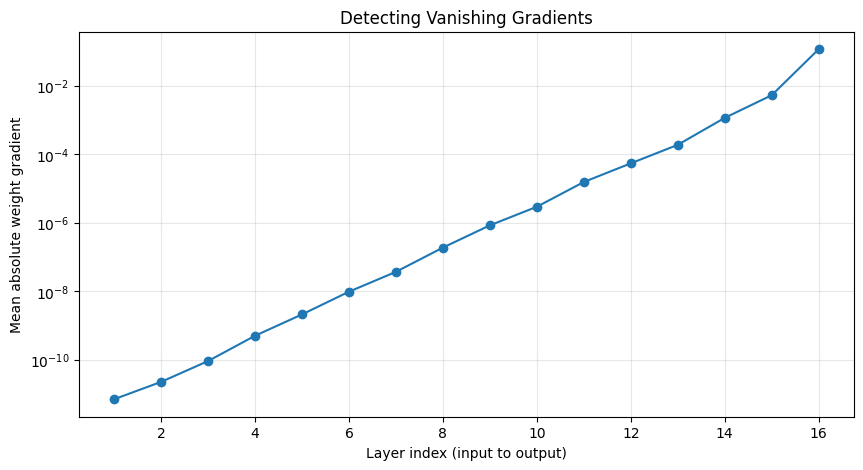

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(gradient_df) + 1),
    gradient_df["mean_abs_gradient"],
    marker="o"
)

plt.yscale("log")
plt.xlabel("Layer index (input to output)")
plt.ylabel("Mean absolute weight gradient")
plt.title("Detecting Vanishing Gradients")
plt.grid(True, alpha=0.3)
plt.show()


Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.3626 - loss: 0.7337 - val_accuracy: 0.4176 - val_loss: 0.7053
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4396 - loss: 0.7000 - val_accuracy: 0.5824 - val_loss: 0.6902
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6374 - loss: 0.6813 - val_accuracy: 0.5824 - val_loss: 0.6833
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6374 - loss: 0.6708 - val_accuracy: 0.5824 - val_loss: 0.6804
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6374 - loss: 0.6648 - val_accuracy: 0.5824 - val_loss: 0.6796
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6374 - loss: 0.6613 - val_accuracy: 0.5824 - val_loss: 0.6796
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6374 - loss: 0.6592 - val_accuracy: 0.5824 - val_loss: 0.6800
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6374 - loss: 0.6579 - val_accuracy: 0.5824 - v

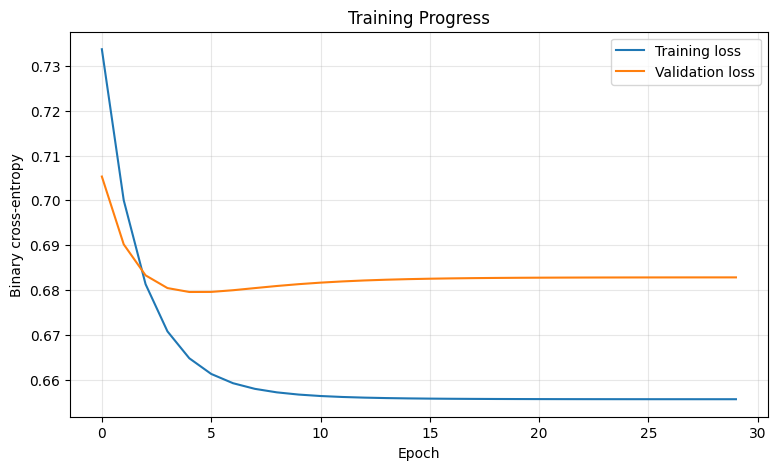

Test loss: 0.6583
Test accuracy: 0.6316


In [15]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training Progress")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))


   layer  before_training  after_training
dense_32     6.957042e-12    5.378939e-12
dense_33     2.236401e-11    5.211996e-12
dense_34     9.096181e-11    1.046121e-11
dense_35     4.988392e-10    4.112282e-11
dense_36     2.099609e-09    2.116014e-10
dense_37     9.696789e-09    9.176236e-10
dense_38     3.697615e-08    3.616299e-09
dense_39     1.888133e-07    1.949103e-08
dense_40     8.457446e-07    9.979867e-08
dense_41     2.955521e-06    3.431067e-07
dense_42     1.564157e-05    1.682860e-06
dense_43     5.502978e-05    6.814562e-06
dense_44     1.911534e-04    2.654985e-05
dense_45     1.175407e-03    1.632485e-04
dense_46     5.398846e-03    7.578068e-04
dense_47     1.195110e-01    1.684491e-02


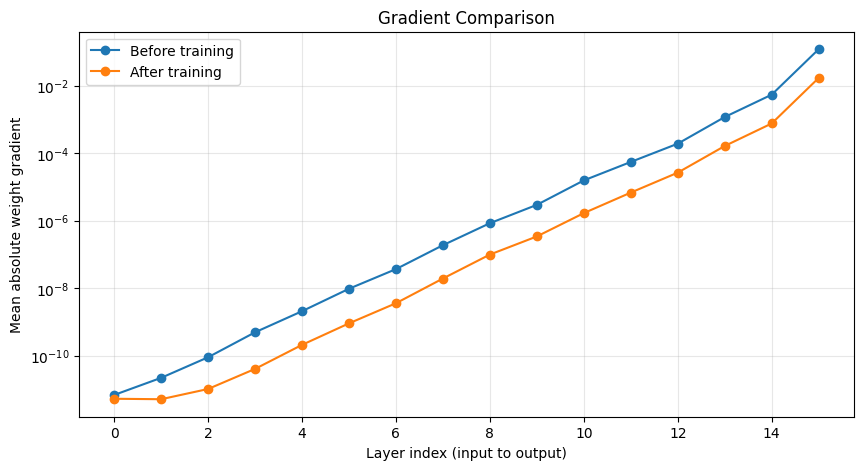

In [16]:
after_df, after_loss = get_layer_gradients(
    model, X_train, y_train
)

comparison = pd.DataFrame({
    "layer": gradient_df["layer"],
    "before_training": gradient_df["mean_abs_gradient"],
    "after_training": after_df["mean_abs_gradient"]
})

print(comparison.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(
    comparison["before_training"],
    marker="o",
    label="Before training"
)
plt.plot(
    comparison["after_training"],
    marker="o",
    label="After training"
)
plt.yscale("log")
plt.xlabel("Layer index (input to output)")
plt.ylabel("Mean absolute weight gradient")
plt.title("Gradient Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Training loss decreases very slowly

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.5824 - val_loss: 0.6828
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6374 - loss: 0.6556 - val_accuracy: 0.58

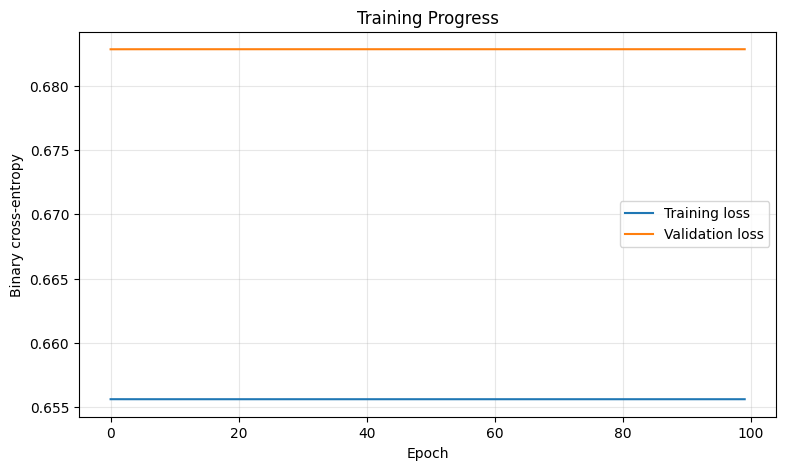

Test loss: 0.6583
Test accuracy: 0.6316


In [18]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training Progress")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

# 3. No change or minimal change in weights

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [20]:
X, y = make_moons(n_samples=500, noise=0.05, random_state=42)

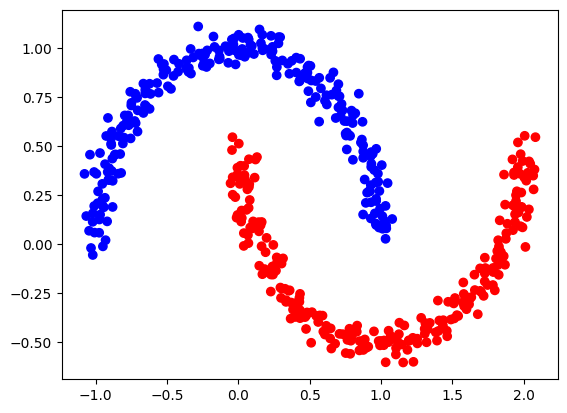

In [21]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr')
plt.show()

In [32]:
model = Sequential()

model.add(Dense(10, activation='sigmoid', input_dim=2))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
old_weights = model.get_weights()[0]

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [35]:
model.fit(X_train, y_train, epochs=100)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5175 - loss: 0.7066
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5175 - loss: 0.6971
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5175 - loss: 0.6933
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5175 - loss: 0.6925
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5175 - loss: 0.6926
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accu

In [36]:
new_weights = model.get_weights()[0]

In [37]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [38]:
gradient

array([[ 39.413807  , -15.830695  ,  -7.967114  ,   8.519351  ,
          0.45490262,  23.9425    , -44.254955  ,   9.081333  ,
         47.65108   , -14.950394  ],
       [-30.112564  ,  12.504338  ,   7.4392405 ,  -7.144391  ,
          0.34254786, -17.409412  ,  34.83033   ,  -6.7291255 ,
        -35.008564  ,  13.621091  ]], dtype=float32)

In [39]:
old_weights

array([[-0.29922205,  0.50273114, -0.6274703 , -0.5110481 , -0.18704718,
         0.16794491,  0.34903473, -0.44324034,  0.07067925, -0.39361987],
       [-0.5720671 ,  0.4228757 ,  0.09857643,  0.36730975,  0.44829458,
        -0.4285259 ,  0.35805553,  0.68381006,  0.05446166,  0.52893704]],
      dtype=float32)

In [40]:
new_weights

array([[-0.33863586,  0.51856184, -0.6195032 , -0.51956743, -0.18750209,
         0.14400241,  0.3932897 , -0.45232168,  0.02302817, -0.37866947],
       [-0.5419545 ,  0.41037136,  0.09113719,  0.37445414,  0.44795203,
        -0.41111648,  0.3232252 ,  0.6905392 ,  0.08947022,  0.51531595]],
      dtype=float32)

In [41]:
percent_change

array([[13.172094  ,  3.1489387 ,  1.2697197 ,  1.6670352 ,  0.24320209,
        14.256163  , 12.679243  ,  2.048851  , 67.41877   ,  3.7981808 ],
       [ 5.263817  ,  2.9569774 ,  7.5466733 ,  1.9450591 ,  0.07641134,
         4.0626283 ,  9.727634  ,  0.9840636 , 64.28112   ,  2.575182  ]],
      dtype=float32)